<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Credit Risk Assessment: Build a credit scoring model to assess the creditworthiness of applicants using historical financial data and perform comparative analysis (Logistic Regression, Random Forest)


### 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

### 2. Load dataset

In [5]:
df = pd.read_csv("/content/credit_risk_assessment_500_samples.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (500, 11)


,Applicant_ID,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs,Credit_Risk
0,1,59,153267,28,818,196649,12,2,0.68,0,High
1,2,49,232745,0,436,175354,60,0,0.23,5,High
2,3,35,974945,19,797,662297,48,3,0.54,0,Medium
3,4,63,307164,29,776,831725,48,0,0.56,4,High
4,5,28,685626,6,893,498625,60,3,0.66,8,High


### 3. Data Preprocessing

In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Drop applicant ID
df = df.drop(columns=['Applicant_ID'])

# Check target distribution
print("\nCredit Risk Distribution:")
print(df['Credit_Risk'].value_counts())

# Check dataset information
print("\nDataset Information:")
print(df.info())

Missing Values:
Applicant_ID               0
Age                        0
Annual_Income              0
Employment_Years           0
Credit_Score               0
Loan_Amount                0
Loan_Term_Months           0
Existing_Loans_Count       0
Debt_to_Income_Ratio       0
Late_Payments_Last_2Yrs    0
Credit_Risk                0
dtype: int64

Credit Risk Distribution:
Credit_Risk
High      315
Medium    164
Low        21
Name: count, dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      500 non-null    int64  
 1   Annual_Income            500 non-null    int64  
 2   Employment_Years         500 non-null    int64  
 3   Credit_Score             500 non-null    int64  
 4   Loan_Amount              500 non-null    int64  
 5   Loan_Term_Months         500 non-nu

### 4. Separate features and target

In [7]:
X = df.drop(columns=['Credit_Risk'])
y = df['Credit_Risk']

print("Features:", X.columns.tolist())
print("\nTarget Classes:", y.unique())

Features: ['Age', 'Annual_Income', 'Employment_Years', 'Credit_Score', 'Loan_Amount', 'Loan_Term_Months', 'Existing_Loans_Count', 'Debt_to_Income_Ratio', 'Late_Payments_Last_2Yrs']

Target Classes: ['High' 'Medium' 'Low']


### 5. Split dataset

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


### 6. Feature scaling

In [9]:
# Logistic Regression preprocessing
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

# Random Forest preprocessing
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    ))
])

### 7. Train Machine Learning models

In [10]:
models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

results = []
trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    trained_models[name] = model

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print("\n", name)

    print(classification_report(
        y_test,
        y_pred,
        labels=['Low', 'Medium', 'High'],
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

         Low       0.50      1.00      0.67         4
      Medium       0.67      0.73      0.70        33
        High       0.91      0.81      0.86        63

    accuracy                           0.79       100
   macro avg       0.69      0.85      0.74       100
weighted avg       0.81      0.79      0.80       100


 Random Forest
              precision    recall  f1-score   support

         Low       1.00      0.75      0.86         4
      Medium       0.97      1.00      0.99        33
        High       1.00      1.00      1.00        63

    accuracy                           0.99       100
   macro avg       0.99      0.92      0.95       100
weighted avg       0.99      0.99      0.99       100



### 8. Comparative analysis

In [11]:
results_df = pd.DataFrame(results)

print("CREDIT RISK MODEL COMPARISON")

display(results_df.round(4))

CREDIT RISK MODEL COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.79,0.6925,0.8456,0.7398
1,Random Forest,0.99,0.9902,0.9167,0.9474


### 9. Visualize model performance

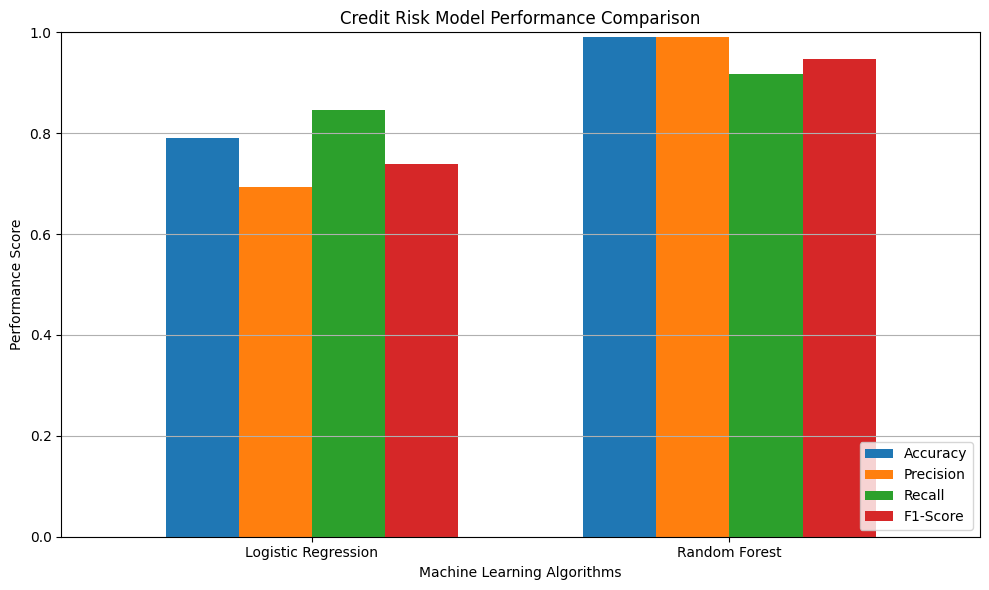

In [12]:
results_df.set_index('Algorithm').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title('Credit Risk Model Performance Comparison')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Performance Score')

plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

### 10. Confusion matrices

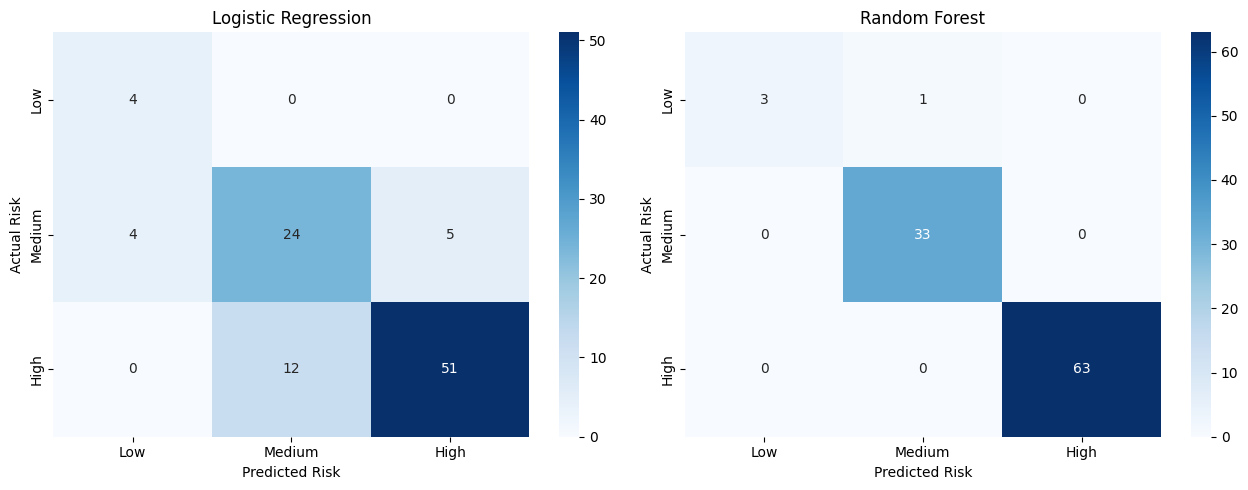

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=['Low', 'Medium', 'High']
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Low', 'Medium', 'High'],
        yticklabels=['Low', 'Medium', 'High'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Risk')
    ax.set_ylabel('Actual Risk')

plt.tight_layout()
plt.show()

### 11. Predict credit risk for a new applicant

In [16]:
def predict_credit_risk():

    print("Enter Applicant Financial Details")

    age = int(input("Age: "))
    income = float(input("Annual Income: "))
    employment = int(input("Employment Years: "))
    credit_score = int(input("Credit Score: "))
    loan_amount = float(input("Loan Amount: "))
    loan_term = int(input("Loan Term (Months): "))
    existing_loans = int(input("Existing Loans Count: "))
    debt_ratio = float(input("Debt-to-Income Ratio: "))
    late_payments = int(input("Late Payments in Last 2 Years: "))

    applicant = pd.DataFrame([{
        'Age': age,
        'Annual_Income': income,
        'Employment_Years': employment,
        'Credit_Score': credit_score,
        'Loan_Amount': loan_amount,
        'Loan_Term_Months': loan_term,
        'Existing_Loans_Count': existing_loans,
        'Debt_to_Income_Ratio': debt_ratio,
        'Late_Payments_Last_2Yrs': late_payments
    }])

    print("\nCredit Risk Predictions:")

    for name, model in trained_models.items():

        prediction = model.predict(applicant)[0]

        print(name, ":", prediction)


predict_credit_risk()

Enter Applicant Financial Details
Age: 30
Annual Income: 100000000
Employment Years: 10
Credit Score: 723
Loan Amount: 5000000
Loan Term (Months): 36
Existing Loans Count: 1000000
Debt-to-Income Ratio: 0.69
Late Payments in Last 2 Years: 0

Credit Risk Predictions:
Logistic Regression : Low
Random Forest : High
